# Aula 6.12 — Desafio: construindo uma rede neural do zero

Roteiro: um **Perceptron** aprende o AND, mostramos por que ele **não resolve o XOR**, e então construímos uma **MLP em NumPy** (forward, perda, backpropagation e treino) que resolve. No final, variamos o número de neurônios ocultos e a taxa de aprendizado, e abrimos a rede para ver **como ela aprendeu**.

Só NumPy e Matplotlib. As 4 linhas da tabela são o conjunto de treino inteiro: o objetivo é aprender a função lógica, não generalizar.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
Y_and = np.array([[0], [0], [0], [1]], dtype=float)
Y_xor = np.array([[0], [1], [1], [0]], dtype=float)

## 1 · Perceptron para AND

Um único neurônio: $z = \mathbf{x}\cdot\mathbf{w} + b$, prevê $+1$ se $z \ge 0$ e $-1$ caso contrário. Quando erra, corrige: $\mathbf{w} \leftarrow \mathbf{w} + \eta\, y_i \mathbf{x}_i$ e $b \leftarrow b + \eta\, y_i$.

In [2]:
def treinar_perceptron(X, y, taxa=0.1, max_epocas=100):
    w, b = np.zeros(X.shape[1]), 0.0
    erros_por_epoca = []
    for epoca in range(max_epocas):
        erros = 0
        for xi, yi in zip(X, y):
            prev = 1 if xi @ w + b >= 0 else -1
            if prev != yi:
                w += taxa * yi * xi
                b += taxa * yi
                erros += 1
        erros_por_epoca.append(erros)
        if erros == 0:
            break
    return w, b, erros_por_epoca

y_and_pm = np.where(Y_and.ravel() == 1, 1, -1)          # 0/1 -> -1/+1
w_and, b_and, erros_and = treinar_perceptron(X, y_and_pm)
prev_and = np.where(X @ w_and + b_and >= 0, 1, -1)

print("Pesos:", w_and, "| bias:", round(b_and, 2), "| épocas:", len(erros_and))
print("Previsto:", prev_and, "| esperado:", y_and_pm)
print("Fronteira: x2 = ", f"{-w_and[0]/w_and[1]:.2f}·x1 + {-b_and/w_and[1]:.2f}")

Pesos: [0.2 0.1] | bias: -0.2 | épocas: 4
Previsto: [-1 -1 -1  1] | esperado: [-1 -1 -1  1]
Fronteira: x2 =  -2.00·x1 + 2.00


## 2 · Por que o Perceptron não resolve o XOR

**Experimento:** treinando por 100 épocas, o número de erros nunca chega a zero.

**Matemática:** para acertar o XOR, o neurônio precisaria de

- $(0,0) \to 0$: $\; b < 0$
- $(0,1) \to 1$: $\; w_2 + b \ge 0$
- $(1,0) \to 1$: $\; w_1 + b \ge 0$
- $(1,1) \to 0$: $\; w_1 + w_2 + b < 0$

Somando a 2ª e a 3ª: $w_1 + w_2 + 2b \ge 0$, ou seja, $w_1 + w_2 + b \ge -b > 0$ (porque $b < 0$). Isso contradiz a 4ª condição. **Não existe reta** que separe as classes do XOR: elas estão em diagonais opostas.

Erros nas últimas 10 épocas: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Menor número de erros em 100 épocas: 3
Acertos finais: 2 de 4


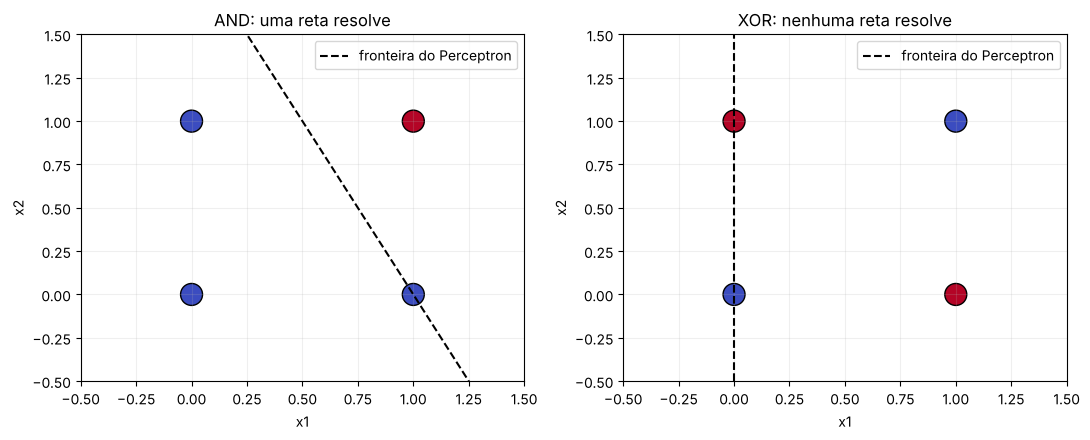

In [3]:
y_xor_pm = np.where(Y_xor.ravel() == 1, 1, -1)
w_x, b_x, erros_xor = treinar_perceptron(X, y_xor_pm, max_epocas=100)
prev_xor = np.where(X @ w_x + b_x >= 0, 1, -1)
print("Erros nas últimas 10 épocas:", erros_xor[-10:])
print("Menor número de erros em 100 épocas:", min(erros_xor))
print("Acertos finais:", np.sum(prev_xor == y_xor_pm), "de 4")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
xs = np.linspace(-0.5, 1.5, 50)
for ax, Yt, w, b, titulo in [(eixos[0], Y_and, w_and, b_and, "AND: uma reta resolve"),
                             (eixos[1], Y_xor, w_x, b_x, "XOR: nenhuma reta resolve")]:
    ax.scatter(X[:, 0], X[:, 1], c=Yt.ravel(), cmap="coolwarm", s=250, edgecolors="black")
    if w[1] != 0:
        ax.plot(xs, -(w[0] * xs + b) / w[1], "k--", label="fronteira do Perceptron")
    else:
        ax.axvline(-b / w[0], color="k", ls="--", label="fronteira do Perceptron")
    ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2", title=titulo)
    ax.legend(loc="upper right"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 3 a 6 · A MLP em NumPy: forward, perda e backpropagation

Arquitetura $2 \to H \to 1$, com sigmoid nas duas camadas.

**Forward:**
$Z^{[1]} = XW^{[1]} + b^{[1]}$, $\;A^{[1]} = \sigma(Z^{[1]})$, $\;Z^{[2]} = A^{[1]}W^{[2]} + b^{[2]}$, $\;A^{[2]} = \sigma(Z^{[2]})$

**Perda (Binary Cross-Entropy):**
$L = -\frac{1}{m}\sum \left[y\log a + (1-y)\log(1-a)\right]$

**Backpropagation (regra da cadeia, de trás para frente):**

| gradiente | fórmula | de onde vem |
|---|---|---|
| $dZ^{[2]}$ | $(A^{[2]} - Y)/m$ | derivada da BCE com a sigmoid: os termos se simplificam |
| $dW^{[2]}$ | $A^{[1]\top} dZ^{[2]}$ | $Z^{[2]}$ depende de $W^{[2]}$ através de $A^{[1]}$ |
| $db^{[2]}$ | $\sum dZ^{[2]}$ | o bias soma em todas as amostras |
| $dA^{[1]}$ | $dZ^{[2]} W^{[2]\top}$ | o erro volta pelos mesmos pesos |
| $dZ^{[1]}$ | $dA^{[1]} \odot A^{[1]}(1-A^{[1]})$ | derivada da sigmoid: $\sigma'(z) = \sigma(z)(1-\sigma(z))$ |
| $dW^{[1]}$, $db^{[1]}$ | $X^\top dZ^{[1]}$, $\sum dZ^{[1]}$ | igual à camada de saída |

**Atualização:** $\theta \leftarrow \theta - \eta \nabla_\theta L$

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def bce(Y, A):
    A = np.clip(A, 1e-12, 1 - 1e-12)
    return float(-np.mean(Y * np.log(A) + (1 - Y) * np.log(1 - A)))


class MLP:
    def __init__(self, n_ocultos=4, taxa=0.5, epocas=10000, semente=42):
        self.n_ocultos, self.taxa, self.epocas, self.semente = n_ocultos, taxa, epocas, semente

    def _inicializar(self, n_entradas):
        rng = np.random.default_rng(self.semente)
        self.params = {
            "W1": rng.normal(0, 0.8, size=(n_entradas, self.n_ocultos)),
            "b1": np.zeros((1, self.n_ocultos)),
            "W2": rng.normal(0, 0.8, size=(self.n_ocultos, 1)),
            "b2": np.zeros((1, 1)),
        }

    def forward(self, X):                                    # 4
        p = self.params
        A1 = sigmoid(X @ p["W1"] + p["b1"])
        A2 = sigmoid(A1 @ p["W2"] + p["b2"])
        return A2, {"X": X, "A1": A1, "A2": A2}

    def backward(self, Y, cache):                            # 6
        m = len(Y)
        X, A1, A2 = cache["X"], cache["A1"], cache["A2"]
        dZ2 = (A2 - Y) / m
        dA1 = dZ2 @ self.params["W2"].T
        dZ1 = dA1 * A1 * (1 - A1)
        return {"W1": X.T @ dZ1, "b1": dZ1.sum(axis=0, keepdims=True),
                "W2": A1.T @ dZ2, "b2": dZ2.sum(axis=0, keepdims=True)}

    def fit(self, X, Y):                                     # 7
        self._inicializar(X.shape[1])
        self.historico_ = []
        for _ in range(self.epocas):
            A2, cache = self.forward(X)
            self.historico_.append(bce(Y, A2))               # 5
            grads = self.backward(Y, cache)
            for k in self.params:
                self.params[k] -= self.taxa * grads[k]
        self.perda_final_ = bce(Y, self.forward(X)[0])
        return self

    def predict_proba(self, X):
        return self.forward(X)[0]

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

### Conferindo o backpropagation

Se as derivadas estiverem certas, elas batem com o **gradiente numérico** (diferença central): mexer um pouquinho em cada peso e ver quanto a perda muda.

In [5]:
rede = MLP(n_ocultos=4, semente=42)
rede._inicializar(2)
A2, cache = rede.forward(X)
grads = rede.backward(Y_xor, cache)

h, maior_dif = 1e-6, 0.0
for nome, P in rede.params.items():
    for idx in np.ndindex(P.shape):
        original = P[idx]
        P[idx] = original + h; mais = bce(Y_xor, rede.forward(X)[0])
        P[idx] = original - h; menos = bce(Y_xor, rede.forward(X)[0])
        P[idx] = original
        maior_dif = max(maior_dif, abs((mais - menos) / (2 * h) - grads[nome][idx]))

print("Maior diferença entre gradiente analítico e numérico:", f"{maior_dif:.2e}")
assert maior_dif < 1e-7

Maior diferença entre gradiente analítico e numérico: 1.12e-10


## 7 · Treinar a rede (2 → 4 → 1, taxa 0,5, 10 000 épocas)

In [6]:
rede = MLP(n_ocultos=4, taxa=0.5, epocas=10000, semente=42).fit(X, Y_xor)
print(f"Perda: {rede.historico_[0]:.4f} → {rede.perda_final_:.6f}")

Perda: 0.7285 → 0.001610


## 8 · Curva de perda

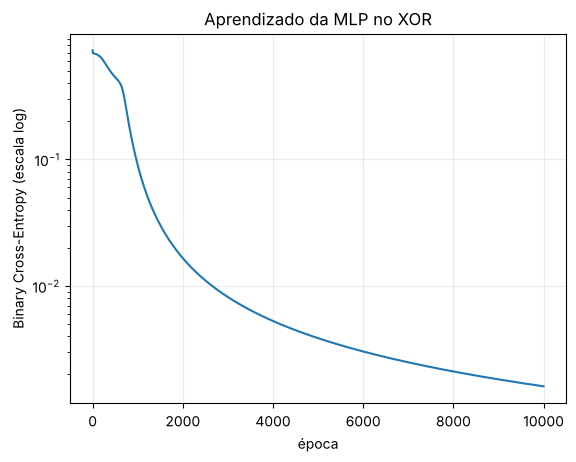

In [7]:
plt.plot(rede.historico_)
plt.yscale("log")
plt.xlabel("época"); plt.ylabel("Binary Cross-Entropy (escala log)")
plt.title("Aprendizado da MLP no XOR"); plt.grid(alpha=0.25)
plt.show()

## 9 · Verificar as previsões

In [8]:
proba = rede.predict_proba(X).ravel()
prev = rede.predict(X).ravel()
print("entrada | probabilidade | previsto | esperado")
for x, p, pr, e in zip(X.astype(int), proba, prev, Y_xor.astype(int).ravel()):
    print(f"{x}  |   {p:.4f}      |    {pr}     |    {e}")
assert np.array_equal(prev, Y_xor.ravel().astype(int))
print("\nA MLP acertou as 4 linhas do XOR.")

entrada | probabilidade | previsto | esperado
[0 0]  |   0.0004      |    0     |    0
[0 1]  |   0.9987      |    1     |    1
[1 0]  |   0.9981      |    1     |    1
[1 1]  |   0.0028      |    0     |    0

A MLP acertou as 4 linhas do XOR.


## 10 · Variar o número de neurônios ocultos

Para cada tamanho, treinamos com **10 sementes** diferentes (10 000 épocas, taxa 0,5) e contamos em quantas a rede acertou as 4 linhas do XOR.

 ocultos |  acertou XOR |  perda final (mediana)


       1 |         0/10 |                0.47867


       2 |         9/10 |                0.00221


       3 |        10/10 |                0.00195


       4 |        10/10 |                0.00154


       8 |        10/10 |                0.00110


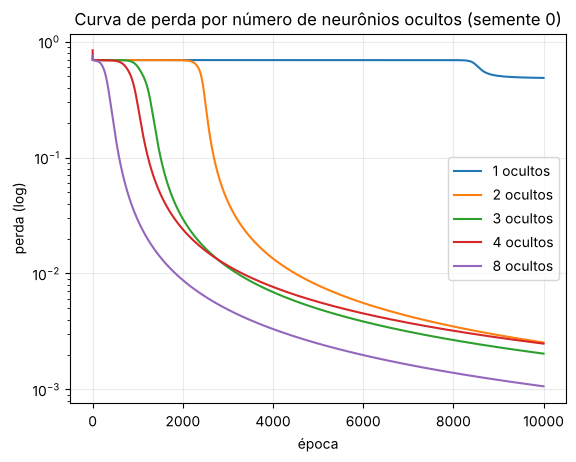

In [9]:
print(f"{'ocultos':>8} | {'acertou XOR':>12} | {'perda final (mediana)':>22}")
resultados_h = {}
for H in [1, 2, 3, 4, 8]:
    redes = [MLP(n_ocultos=H, taxa=0.5, epocas=10000, semente=s).fit(X, Y_xor) for s in range(10)]
    acertos = sum(np.array_equal(r.predict(X).ravel(), Y_xor.ravel()) for r in redes)
    mediana = np.median([r.perda_final_ for r in redes])
    resultados_h[H] = redes[0].historico_
    print(f"{H:>8} | {acertos:>9}/10 | {mediana:>22.5f}")

for H, hist in resultados_h.items():
    plt.plot(hist, label=f"{H} ocultos")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda (log)")
plt.title("Curva de perda por número de neurônios ocultos (semente 0)")
plt.legend(); plt.grid(alpha=0.25); plt.show()

## 11 · Variar a taxa de aprendizado (4 ocultos, 10 sementes)

  taxa |  acertou XOR |  perda final (mediana)


  0.01 |         2/10 |                0.67885


   0.1 |        10/10 |                0.01138


   0.5 |        10/10 |                0.00154


   2.0 |        10/10 |                0.00033


  10.0 |        10/10 |                0.00009


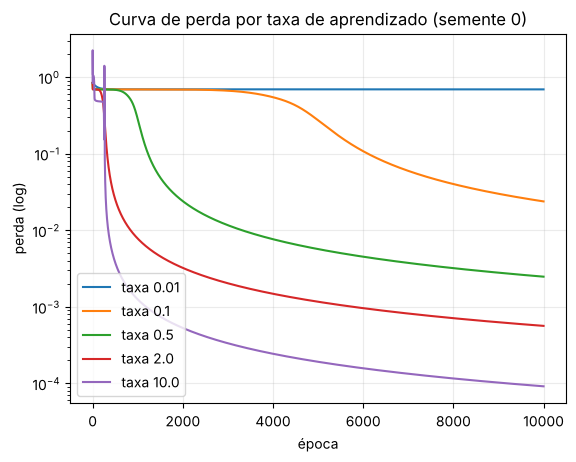

In [10]:
print(f"{'taxa':>6} | {'acertou XOR':>12} | {'perda final (mediana)':>22}")
resultados_t = {}
for taxa in [0.01, 0.1, 0.5, 2.0, 10.0]:
    redes = [MLP(n_ocultos=4, taxa=taxa, epocas=10000, semente=s).fit(X, Y_xor) for s in range(10)]
    acertos = sum(np.array_equal(r.predict(X).ravel(), Y_xor.ravel()) for r in redes)
    resultados_t[taxa] = redes[0].historico_
    print(f"{taxa:>6} | {acertos:>9}/10 | {np.median([r.perda_final_ for r in redes]):>22.5f}")

for taxa, hist in resultados_t.items():
    plt.plot(hist, label=f"taxa {taxa}")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda (log)")
plt.title("Curva de perda por taxa de aprendizado (semente 0)")
plt.legend(); plt.grid(alpha=0.25); plt.show()

## 12 · Como a rede aprendeu

Para enxergar o que acontece por dentro, usamos a menor rede que funciona: **2 neurônios ocultos**. A camada oculta transforma cada entrada $(x_1, x_2)$ em um novo ponto $(h_1, h_2)$. Se o XOR ficar separável por uma reta **nesse novo espaço**, o neurônio de saída, que é só um Perceptron com sigmoid, consegue resolver.

semente usada: 0
entrada | h1     | h2     | saída | XOR
[0 0]  | 0.974  | 0.028  | 0.002 | 0
[0 1]  | 1.000  | 0.959  | 0.998 | 1
[1 0]  | 0.027  | 0.000  | 0.997 | 1
[1 1]  | 0.979  | 0.021  | 0.002 | 0


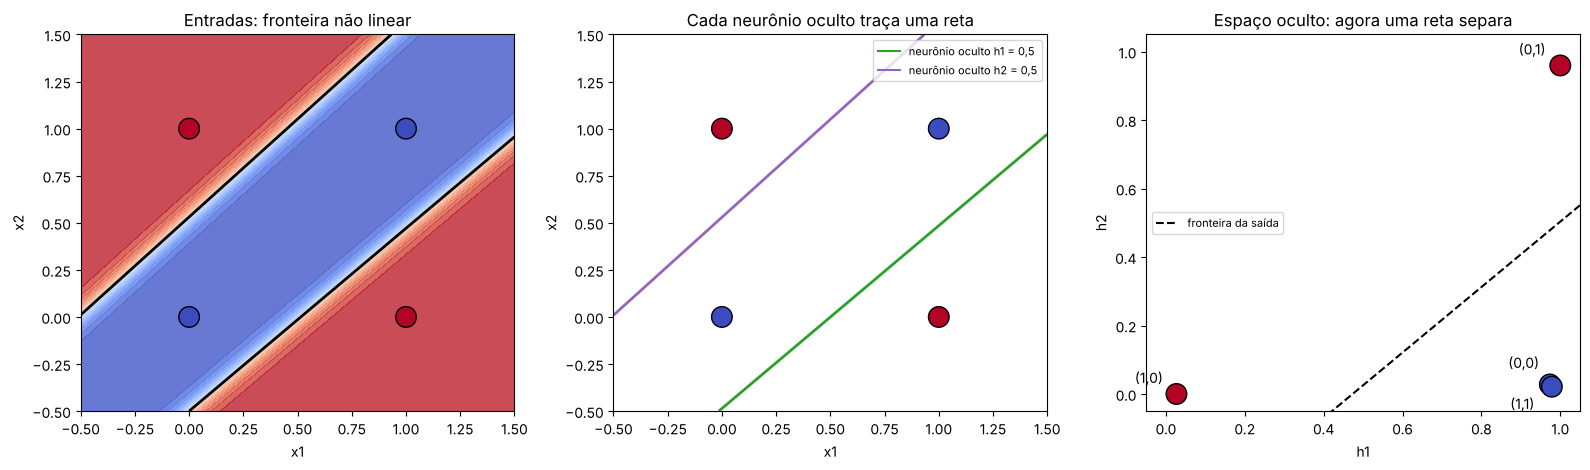

In [11]:
pequena = next(r for r in (MLP(n_ocultos=2, taxa=0.5, epocas=10000, semente=s).fit(X, Y_xor)
                           for s in range(50))
               if np.array_equal(r.predict(X).ravel(), Y_xor.ravel()))
_, cache = pequena.forward(X)
H = cache["A1"]

print("semente usada:", pequena.semente)
print("entrada | h1     | h2     | saída | XOR")
for x, h, a, e in zip(X.astype(int), H, cache["A2"].ravel(), Y_xor.astype(int).ravel()):
    print(f"{x}  | {h[0]:.3f}  | {h[1]:.3f}  | {a:.3f} | {e}")

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))
g = np.linspace(-0.5, 1.5, 300)
G1, G2 = np.meshgrid(g, g)
grade = np.column_stack([G1.ravel(), G2.ravel()])
saida = pequena.predict_proba(grade).reshape(G1.shape)

# (a) entradas originais e a fronteira curva da rede
eixos[0].contourf(G1, G2, saida, levels=20, cmap="coolwarm", alpha=0.8)
eixos[0].contour(G1, G2, saida, levels=[0.5], colors="black", linewidths=2)
eixos[0].scatter(X[:, 0], X[:, 1], c=Y_xor.ravel(), cmap="coolwarm", s=220, edgecolors="black")
eixos[0].set(title="Entradas: fronteira não linear", xlabel="x1", ylabel="x2")

# (b) o que cada neurônio oculto "vê": cada um é uma reta no espaço original
for j, cor in enumerate(["tab:green", "tab:purple"]):
    h_j = sigmoid(grade @ pequena.params["W1"][:, j] + pequena.params["b1"][0, j]).reshape(G1.shape)
    eixos[1].contour(G1, G2, h_j, levels=[0.5], colors=cor, linewidths=2)
    eixos[1].plot([], [], color=cor, label=f"neurônio oculto h{j+1} = 0,5")
eixos[1].scatter(X[:, 0], X[:, 1], c=Y_xor.ravel(), cmap="coolwarm", s=220, edgecolors="black")
eixos[1].set(title="Cada neurônio oculto traça uma reta", xlabel="x1", ylabel="x2",
             xlim=(-0.5, 1.5), ylim=(-0.5, 1.5))
eixos[1].legend(loc="upper right", fontsize=8)

# (c) espaço oculto: o XOR virou linearmente separável
w2, b2 = pequena.params["W2"].ravel(), pequena.params["b2"][0, 0]
hs = np.linspace(-0.05, 1.05, 50)
eixos[2].plot(hs, -(w2[0] * hs + b2) / w2[1], "k--", label="fronteira da saída")
eixos[2].scatter(H[:, 0], H[:, 1], c=Y_xor.ravel(), cmap="coolwarm", s=220, edgecolors="black")
for (a, b), h, dy in zip(X.astype(int), H, [12, 8, 8, -16]):
    eixos[2].annotate(f"({a},{b})", h, xytext=(-30, dy), textcoords="offset points")
eixos[2].set(title="Espaço oculto: agora uma reta separa", xlabel="h1", ylabel="h2",
             xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
eixos[2].legend(loc="center left", fontsize=8)
plt.tight_layout(); plt.show()

### O que o gráfico mostra

- **Cada neurônio oculto é uma reta** no espaço de entrada (gráfico do meio). O $h_1$ fica perto de 0 só do lado da reta verde onde está o ponto (1,0): ele "detecta" a entrada (1,0). O $h_2$ fica perto de 1 só do lado da reta roxa onde está (0,1): ele "detecta" a entrada (0,1).
- **A camada oculta muda as coordenadas** (gráfico da direita). As entradas (0,0) e (1,1), que são classe 0, vão parar praticamente no mesmo ponto, $(h_1, h_2) \approx (0{,}98;\ 0{,}02)$. Já (0,1) e (1,0) vão para cantos opostos. Nesse novo espaço, **uma única reta** separa as classes.
- **O neurônio de saída é só um Perceptron com sigmoid** trabalhando no espaço oculto. Ele responde 1 quando "$h_2$ está alto **ou** $h_1$ está baixo", ou seja, quando a entrada é (0,1) ou (1,0): exatamente o XOR.
- Juntando as duas retas, a fronteira no espaço original vira uma **faixa diagonal** (gráfico da esquerda), algo que nenhum Perceptron sozinho consegue desenhar.

## Conclusão

**Como a rede aprendeu.** Ninguém programou as retas: começaram com pesos aleatórios. Em cada época, o *forward* calcula a saída, a *Binary Cross-Entropy* mede o erro e o *backpropagation* usa a regra da cadeia para descobrir quanto cada peso contribuiu para esse erro, de trás para frente ($dZ^{[2]} = A^{[2]} - Y$, depois $dZ^{[1]} = dZ^{[2]}W^{[2]\top} \odot \sigma'$). O gradiente descendente move cada peso um pouco no sentido que reduz a perda. Depois de milhares de passos, as duas retas ocultas se posicionaram de forma a tornar o XOR separável para o neurônio de saída. O gradiente analítico bateu com o numérico (diferença de $10^{-10}$), o que confirma que as derivadas estão corretas.

**Neurônios ocultos.** Com **1 neurônio oculto, a rede nunca resolve o XOR** (0 de 10): com uma reta só, ela tem o mesmo limite do Perceptron. Com **2** já funciona em 9 de 10 sementes; a que falhou ficou presa num mínimo local. Com **3 ou mais**, acerta sempre e a perda cai mais rápido. Mais neurônios dão mais "retas" para combinar e mais caminhos para o gradiente encontrar uma solução.

**Taxa de aprendizado.** Com **0,01**, a rede quase não sai do lugar em 10 000 épocas (perda ≈ 0,68, perto do chute inicial; só 2 de 10 acertam). Com **0,1**, ela fica parada num platô por umas 5 000 épocas antes de aprender. Entre **0,5 e 2**, aprende rápido e de forma estável. Com **10**, é a mais rápida, mas a curva dá **saltos no começo**: neste problema minúsculo ela se recupera, mas em problemas maiores uma taxa tão alta costuma fazer a perda oscilar ou divergir.

**Resumo:** o Perceptron só traça uma reta, por isso resolve AND e não resolve XOR. A MLP resolve porque a camada oculta, com ativação não linear, **transforma os dados num espaço onde o problema vira linear**. E é o backpropagation que encontra essa transformação sozinho, a partir dos exemplos.